# Comparative Analysis of Machine Learning Models for Breast Cancer Classification

## 1. Introduction

This notebook focuses on comparing the performance of seven machine learning classification algorithms on the Breast Cancer Wisconsin (Diagnostic) dataset.

The models evaluated are:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)
5. K-Nearest Neighbors (KNN)
6. Gaussian Naive Bayes
7. XGBoost

We compare each model's baseline performance with its performance after hyperparameter tuning.

## 2. Objectives

- Compare the performance of different machine learning algorithms.
- Evaluate the effect of hyperparameter tuning.
- Analyze Accuracy, Precision, Recall, F1-score and ROC-AUC.
- Identify models that perform well across different evaluation metrics.
- Understand the strengths and limitations of each algorithm.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## 3. Importing Required Libraries

We import the following Python libraries:

- Pandas: For organizing and analyzing model evaluation results.
- Matplotlib: For creating visual comparisons and charts.
- NumPy: For performing numerical calculations.

These libraries will help us analyze and visualize
the performance of all seven machine learning models.

## 4. Baseline vs Tuned Model Performance

We compare the performance of seven machine learning
models before and after hyperparameter tuning.

The comparison considers five evaluation metrics:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

All results are based on the same training and testing split.

In [2]:
comparison_data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN",
        "Naive Bayes",
        "XGBoost"
    ],

    "Baseline Accuracy": [98.25, 91.23, 95.61, 97.37, 95.61, 93.86, 94.74],
    "Tuned Accuracy":    [97.37, 92.11, 95.61, 98.25, 97.37, 93.86, 94.74],

    "Baseline Precision": [97.62, 84.78, 95.12, 95.35, 95.12, 92.68, 95.00],
    "Tuned Precision":    [97.56, 86.67, 95.12, 97.62, 100.00, 92.68, 95.00],

    "Baseline Recall": [97.62, 92.86, 92.86, 97.62, 92.86, 90.48, 90.48],
    "Tuned Recall":    [95.24, 92.86, 92.86, 97.62, 92.86, 90.48, 90.48],

    "Baseline F1": [97.62, 88.64, 93.98, 96.47, 93.98, 91.57, 92.68],
    "Tuned F1":    [96.39, 89.66, 93.98, 97.62, 96.30, 91.57, 92.68],

    "Baseline ROC-AUC": [0.9954, 0.9157, 0.9937, 0.9964, 0.9788, 0.9878, 0.9934],
    "Tuned ROC-AUC":    [0.9957, 0.9163, 0.9931, 0.9937, 0.9884, 0.9878, 0.9921]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Model,Baseline Accuracy,Tuned Accuracy,Baseline Precision,Tuned Precision,Baseline Recall,Tuned Recall,Baseline F1,Tuned F1,Baseline ROC-AUC,Tuned ROC-AUC
0,Logistic Regression,98.25,97.37,97.62,97.56,97.62,95.24,97.62,96.39,0.9954,0.9957
1,Decision Tree,91.23,92.11,84.78,86.67,92.86,92.86,88.64,89.66,0.9157,0.9163
2,Random Forest,95.61,95.61,95.12,95.12,92.86,92.86,93.98,93.98,0.9937,0.9931
3,SVM,97.37,98.25,95.35,97.62,97.62,97.62,96.47,97.62,0.9964,0.9937
4,KNN,95.61,97.37,95.12,100.00,92.86,92.86,93.98,96.30,0.9788,0.9884
5,Naive Bayes,93.86,93.86,92.68,92.68,90.48,90.48,91.57,91.57,0.9878,0.9878
6,XGBoost,94.74,94.74,95.00,95.00,90.48,90.48,92.68,92.68,0.9934,0.9921


## 5. Performance Improvement After Hyperparameter Tuning

We calculate the difference between tuned and baseline
performance for every evaluation metric.

A positive difference indicates improvement, while
a negative difference indicates a decline.

A zero difference means that the model's performance
remained unchanged.

In [3]:
# Create a copy of our comparison DataFrame
improvement_df = comparison_df[["Model"]].copy()

# Calculate improvement for each metric
improvement_df["Accuracy Change"] = (
    comparison_df["Tuned Accuracy"] -
    comparison_df["Baseline Accuracy"]
)

improvement_df["Precision Change"] = (
    comparison_df["Tuned Precision"] -
    comparison_df["Baseline Precision"]
)

improvement_df["Recall Change"] = (
    comparison_df["Tuned Recall"] -
    comparison_df["Baseline Recall"]
)

improvement_df["F1 Change"] = (
    comparison_df["Tuned F1"] -
    comparison_df["Baseline F1"]
)

improvement_df["ROC-AUC Change"] = (
    comparison_df["Tuned ROC-AUC"] -
    comparison_df["Baseline ROC-AUC"]
)

# Display the improvement table
improvement_df.round(4)

,Model,Accuracy Change,Precision Change,Recall Change,F1 Change,ROC-AUC Change
0,Logistic Regression,-0.88,-0.06,-2.38,-1.23,0.0003
1,Decision Tree,0.88,1.89,0.00,1.02,0.0006
2,Random Forest,0.00,0.00,0.00,0.00,-0.0006
3,SVM,0.88,2.27,0.00,1.15,-0.0027
4,KNN,1.76,4.88,0.00,2.32,0.0096
5,Naive Bayes,0.00,0.00,0.00,0.00,0.0000
6,XGBoost,0.00,0.00,0.00,0.00,-0.0013


## 6. Baseline vs Tuned Accuracy Comparison

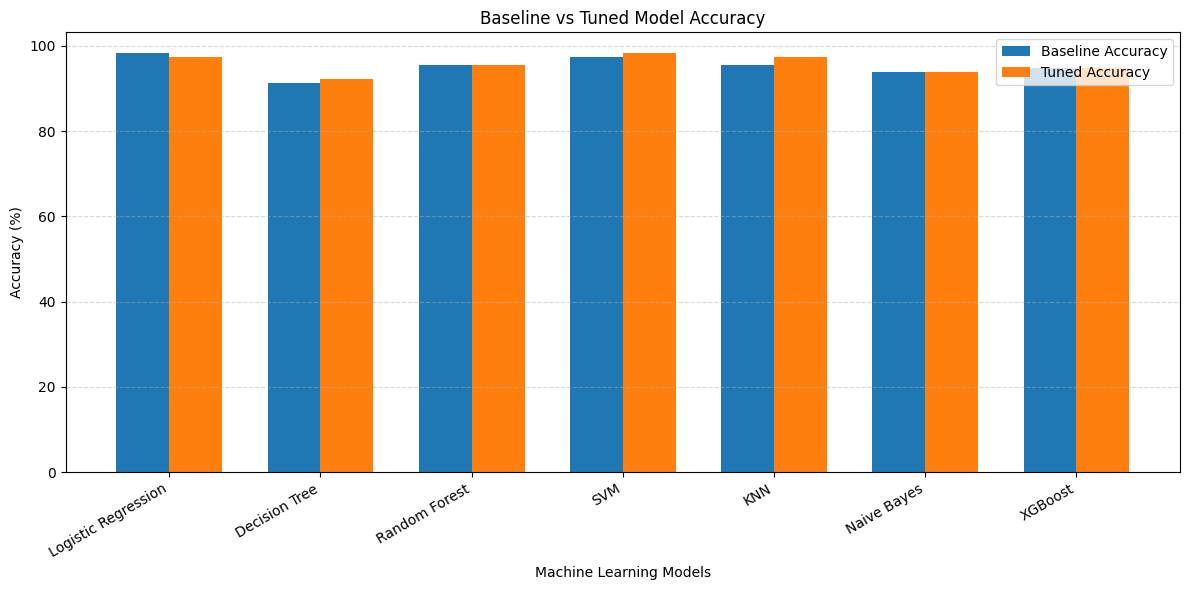

In [4]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Define the positions of the bars
x = np.arange(len(comparison_df["Model"]))

# Width of each bar
width = 0.35

# Plot baseline accuracy
plt.bar(
    x - width/2,
    comparison_df["Baseline Accuracy"],
    width,
    label="Baseline Accuracy"
)

# Plot tuned accuracy
plt.bar(
    x + width/2,
    comparison_df["Tuned Accuracy"],
    width,
    label="Tuned Accuracy"
)

# Add labels and title
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Tuned Model Accuracy")

# Set model names on the x-axis
plt.xticks(x, comparison_df["Model"], rotation=30, ha="right")

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### Accuracy Comparison - Interpretation

The grouped bar chart compares baseline and tuned accuracy
across all seven machine learning models.

Observations:

- Logistic Regression experienced a slight decrease in accuracy.
- Decision Tree showed an improvement after tuning.
- Random Forest maintained the same accuracy.
- SVM showed an improvement after tuning.
- KNN showed the largest accuracy improvement.
- Naive Bayes maintained the same accuracy.
- XGBoost maintained the same accuracy.

KNN improved from 95.61% to 97.37%, representing
an increase of 1.76 percentage points.

Overall, hyperparameter tuning affected different models
in different ways.

## 7. Baseline vs Tuned Malignant Precision Comparison

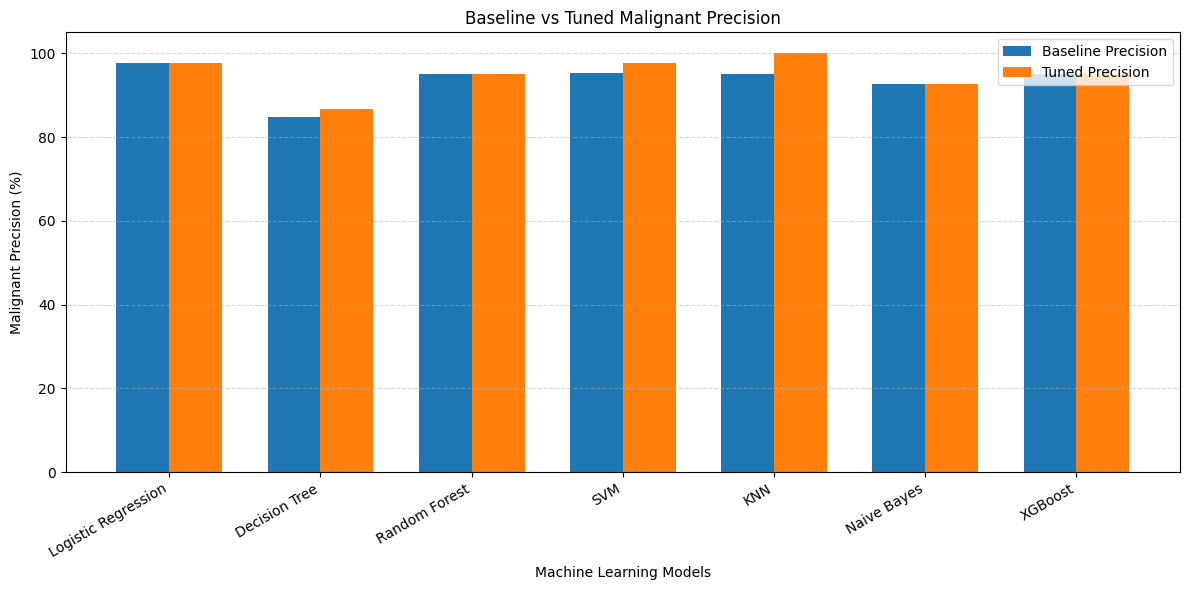

In [5]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Define positions for the models
x = np.arange(len(comparison_df["Model"]))

# Width of each bar
width = 0.35

# Plot baseline precision
plt.bar(
    x - width/2,
    comparison_df["Baseline Precision"],
    width,
    label="Baseline Precision"
)

# Plot tuned precision
plt.bar(
    x + width/2,
    comparison_df["Tuned Precision"],
    width,
    label="Tuned Precision"
)

# Add chart title and labels
plt.xlabel("Machine Learning Models")
plt.ylabel("Malignant Precision (%)")
plt.title("Baseline vs Tuned Malignant Precision")

# Display model names
plt.xticks(x, comparison_df["Model"], rotation=30, ha="right")

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### Malignant Precision Comparison

The grouped bar chart compares baseline and tuned
malignant precision across all seven models.

Observations:

- KNN achieved the highest tuned precision of 100%.
- SVM improved from 95.35% to 97.62%.
- Decision Tree improved from 84.78% to 86.67%.
- Random Forest, Naive Bayes and XGBoost showed no change.
- Logistic Regression experienced a negligible decrease.

KNN's 100% precision indicates that none of its
predicted malignant cases were actually benign
in this particular test set.

However, precision must be interpreted alongside
recall to understand the complete classification performance.

## 8. Baseline vs Tuned Malignant Recall Comparison

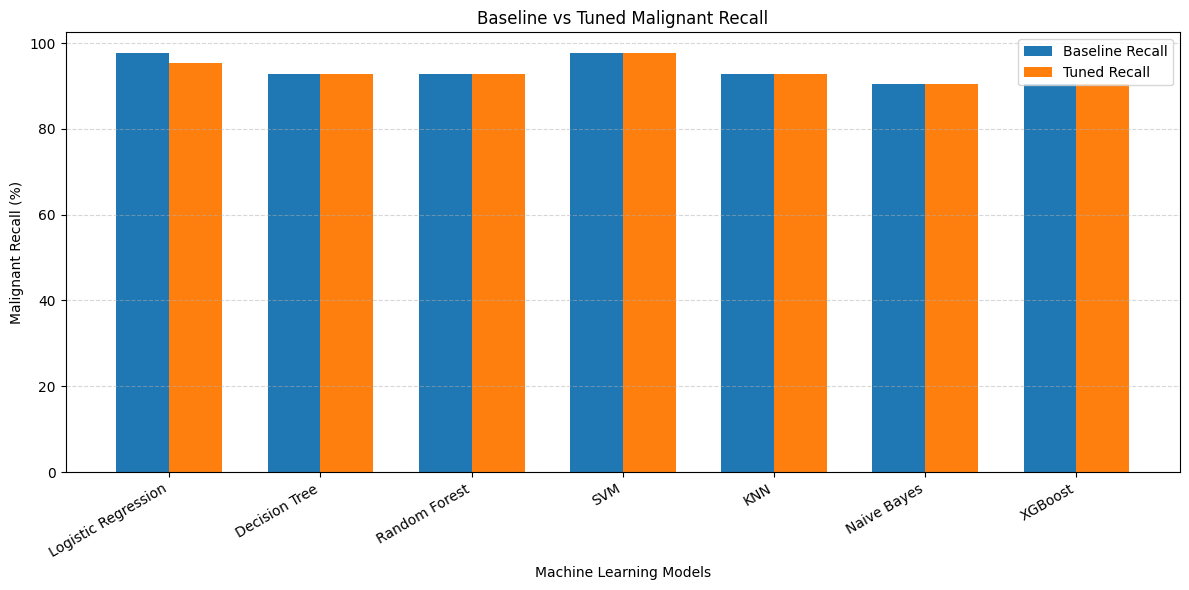

In [6]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Define positions for the models
x = np.arange(len(comparison_df["Model"]))

# Width of each bar
width = 0.35

# Plot baseline recall
plt.bar(
    x - width/2,
    comparison_df["Baseline Recall"],
    width,
    label="Baseline Recall"
)

# Plot tuned recall
plt.bar(
    x + width/2,
    comparison_df["Tuned Recall"],
    width,
    label="Tuned Recall"
)

# Add chart title and labels
plt.xlabel("Machine Learning Models")
plt.ylabel("Malignant Recall (%)")
plt.title("Baseline vs Tuned Malignant Recall")

# Display model names
plt.xticks(x, comparison_df["Model"], rotation=30, ha="right")

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### Malignant Recall Comparison
The grouped bar chart compares baseline and tuned
malignant recall across all seven models.

Observations:

- SVM maintained the highest tuned recall of 97.62%.
- Logistic Regression decreased from 97.62% to 95.24%.
- Decision Tree, Random Forest and KNN maintained
  their recall at 92.86%.
- Naive Bayes and XGBoost maintained their recall
  at 90.48%.

Recall measures the model's ability to identify
actual malignant samples.

A higher recall indicates fewer missed malignant
cases in this test dataset.

This is an educational comparison and does not
establish clinical suitability.

## 9. Baseline vs Tuned F1-Score Comparison

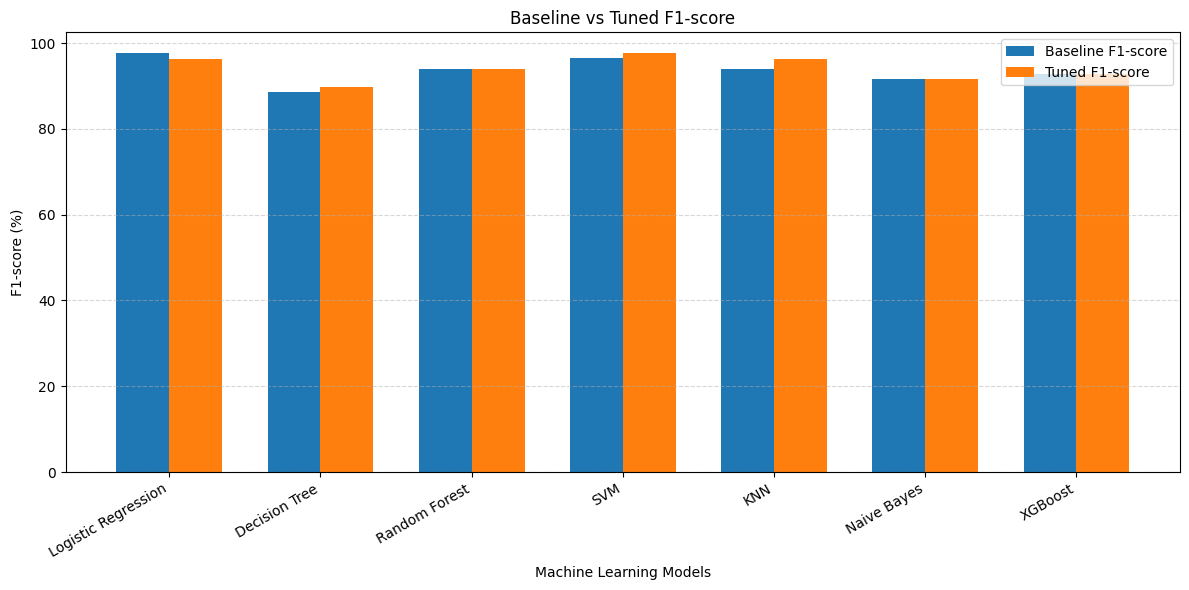

In [7]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Define positions for the models
x = np.arange(len(comparison_df["Model"]))

# Width of each bar
width = 0.35

# Plot baseline F1-score
plt.bar(
    x - width/2,
    comparison_df["Baseline F1"],
    width,
    label="Baseline F1-score"
)

# Plot tuned F1-score
plt.bar(
    x + width/2,
    comparison_df["Tuned F1"],
    width,
    label="Tuned F1-score"
)

# Add chart title and labels
plt.xlabel("Machine Learning Models")
plt.ylabel("F1-score (%)")
plt.title("Baseline vs Tuned F1-score")

# Display model names
plt.xticks(x, comparison_df["Model"], rotation=30, ha="right")

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### F1-score Comparison
The grouped bar chart compares baseline and tuned
F1-scores across all seven models.

Observations:

- SVM achieved the highest tuned F1-score of 97.62%.
- KNN improved from 93.98% to 96.30%.
- Decision Tree improved from 88.64% to 89.66%.
- Logistic Regression decreased from 97.62% to 96.39%.
- Random Forest, Naive Bayes and XGBoost showed no change.

F1-score provides a balance between precision and recall.

SVM demonstrated the strongest overall balance between
these two metrics among the tuned models.

## 10. Baseline vs Tuned ROC-AUC Comparison

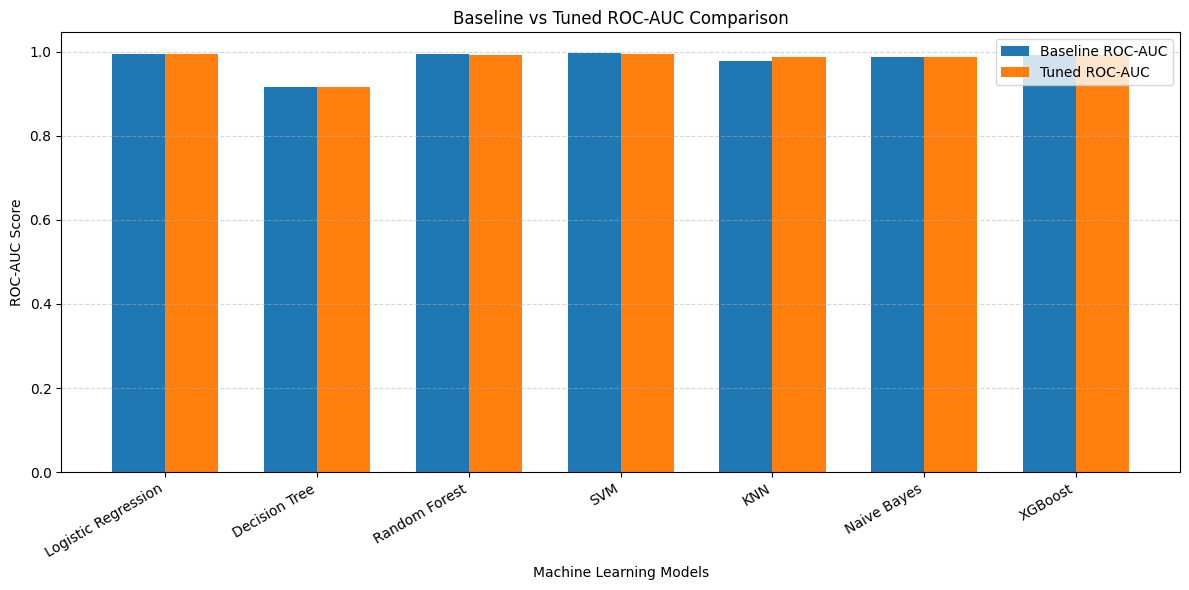

In [8]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Define positions for the models
x = np.arange(len(comparison_df["Model"]))

# Width of each bar
width = 0.35

# Plot baseline ROC-AUC
plt.bar(
    x - width/2,
    comparison_df["Baseline ROC-AUC"],
    width,
    label="Baseline ROC-AUC"
)

# Plot tuned ROC-AUC
plt.bar(
    x + width/2,
    comparison_df["Tuned ROC-AUC"],
    width,
    label="Tuned ROC-AUC"
)

# Add chart title and labels
plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")
plt.title("Baseline vs Tuned ROC-AUC Comparison")

# Display model names
plt.xticks(x, comparison_df["Model"], rotation=30, ha="right")

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### ROC-AUC Comparison
The grouped bar chart compares baseline and tuned
ROC-AUC scores across all seven models.

Observations:

- Logistic Regression improved slightly from 0.9954 to 0.9957.
- Decision Tree improved from 0.9157 to 0.9163.
- KNN showed the largest improvement, from 0.9788 to 0.9884.
- Random Forest decreased slightly from 0.9937 to 0.9931.
- SVM decreased from 0.9964 to 0.9937.
- Naive Bayes remained unchanged at 0.9878.
- XGBoost decreased from 0.9934 to 0.9921.

ROC-AUC evaluates how effectively a model distinguishes
between malignant and benign samples across different
classification thresholds.

Overall, all seven models achieved ROC-AUC scores
above 0.9 on this test dataset.

## 11. Overall Performance Comparison of Tuned Models

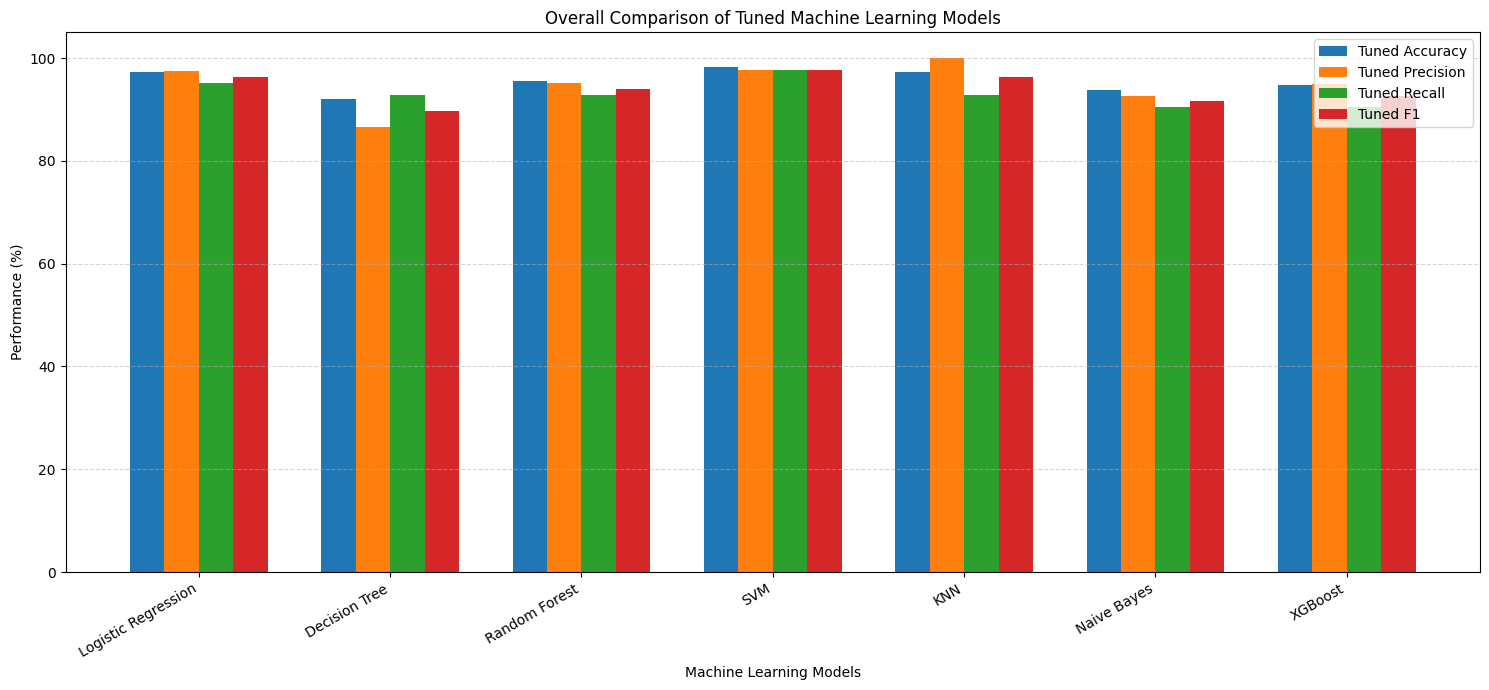

In [9]:
# Select the evaluation metrics
metrics = [
    "Tuned Accuracy",
    "Tuned Precision",
    "Tuned Recall",
    "Tuned F1"
]

# Create the figure
plt.figure(figsize=(15, 7))

# Define positions of the models
x = np.arange(len(comparison_df["Model"]))

# Calculate bar width
width = 0.18

# Plot each metric
for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

# Add labels and title
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance (%)")
plt.title("Overall Comparison of Tuned Machine Learning Models")

# Display model names
plt.xticks(
    x,
    comparison_df["Model"],
    rotation=30,
    ha="right"
)

# Display legend
plt.legend()

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

### Overall Tuned Model Performance - Interpretation

The grouped bar chart compares Accuracy, Precision,
Recall and F1-score across all seven tuned models.

Observations:

- SVM achieved the highest tuned F1-score of 97.62%.
- SVM achieved the highest tuned accuracy of achieved 98.25%.
- KNN achieved the highest tuned precision of 100%.
- SVM achieved the highest tuned malignant recall of 97.62%.
- Decision Tree showed the lowest overall performance
  among the seven models.

The visualization demonstrates that different models
perform differently across evaluation metrics.

Therefore, model selection should consider multiple
metrics rather than accuracy alone.

## 12. Final Ranking of Machine Learning Models

In [10]:
# Sort models by tuned F1-score in descending order
ranking_df = comparison_df[
    ["Model", "Tuned Accuracy", "Tuned Precision",
     "Tuned Recall", "Tuned F1", "Tuned ROC-AUC"]
].sort_values(
    by="Tuned F1",
    ascending=False
).reset_index(drop=True)

# Add ranking positions
ranking_df.insert(
    0,
    "Rank",
    range(1, len(ranking_df) + 1)
)

# Display the ranking table
ranking_df

,Rank,Model,Tuned Accuracy,Tuned Precision,Tuned Recall,Tuned F1,Tuned ROC-AUC
0,1,SVM,98.25,97.62,97.62,97.62,0.9937
1,2,Logistic Regression,97.37,97.56,95.24,96.39,0.9957
2,3,KNN,97.37,100.00,92.86,96.30,0.9884
3,4,Random Forest,95.61,95.12,92.86,93.98,0.9931
4,5,XGBoost,94.74,95.00,90.48,92.68,0.9921
5,6,Naive Bayes,93.86,92.68,90.48,91.57,0.9878
6,7,Decision Tree,92.11,86.67,92.86,89.66,0.9163


### Final Model Ranking
The models are ranked based on their tuned F1-scores.

Observations:

- SVM achieved the highest F1-score of 97.62%.
- Logistic Regression ranked second with 96.39%.
- KNN ranked third with 96.30%.
- Random Forest achieved an F1-score of 93.98%.
- XGBoost achieved an F1-score of 92.68%.
- Naive Bayes achieved an F1-score of 91.57%.
- Decision Tree achieved an F1-score of 89.66%.

SVM demonstrated the strongest balance between
malignant precision and recall in this experiment.

The ranking is based on one test split and should
not be interpreted as a clinical performance ranking.

### Overall Conclusion

In this project, we conducted a comparative study of seven machine learning classification algorithms using the Breast Cancer Wisconsin (Diagnostic) dataset.

The evaluated algorithms were Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Gaussian Naive Bayes and XGBoost.

All models were evaluated using the same training and testing split to ensure a consistent comparison. We initially trained the models using baseline configurations and subsequently applied GridSearchCV with 5-fold cross-validation to identify suitable hyperparameter configurations.

**Key Findings**

1. **SVM:** Achieved the highest tuned F1-score of 97.62%, with 98.25% accuracy and 97.62% malignant recall.

2. **Logistic Regression:** Achieved 97.37% tuned accuracy and a ROC-AUC score of 0.9957, demonstrating strong classification performance.

3. **KNN:** Achieved the highest tuned malignant precision of 100% and improved its accuracy from 95.61% to 97.37%.

4. **Decision Tree:** Showed modest improvements in accuracy, precision and F1-score after hyperparameter tuning.

5. **Random Forest:** Maintained the same classification metrics after tuning, with 95.61% accuracy.

6. **Gaussian Naive Bayes:** Produced unchanged results because GridSearchCV selected its default `var_smoothing` value of 1e-09.

7. **XGBoost:** Maintained the same classification metrics after tuning, with 94.74% accuracy.

**Effect of Hyperparameter Tuning**

The experiments demonstrated that hyperparameter tuning does not guarantee improved performance for every model. Some models improved, some remained unchanged, and others experienced slight decreases in certain evaluation metrics.

**Final Observation**

Among the evaluated models, SVM demonstrated the strongest balance between malignant precision and recall based on the tuned F1-score.

However, the most suitable model depends on the evaluation objective and the importance assigned to different metrics.

This study is an educational machine learning experiment and its results should not be interpreted as evidence of clinical suitability or used for actual medical diagnosis.

**Future Scope**

- Perform repeated stratified cross-validation for more reliable performance estimates.
- Explore additional hyperparameter combinations.
- Investigate feature selection and dimensionality reduction.
- Apply explainability techniques such as SHAP.
- Evaluate model generalization using independent datasets.